# 05 — Verifica: valore concesso per difensore

**La domanda.** Sui nostri dati, la regola di *coinvolgimento* di *Blame is easier
than praise* (Bischofberger et al. 2025, §3.1) produce un segnale utilizzabile?
Cioè: copre i passaggi, poggia su difensori osservati, è stabile fra partite, e
non dipende tutto dall'EPV chiuso di SkillCorner?

È la verifica della scheda
[Verifica sui dati — valore concesso per difensore](https://github.com/lollokomotiv/sport_code_repo/issues/8)
della mappa wayfinder. È un prototipo: serve a decidere se la pista regge, non a
produrre il risultato. Termini come nel glossario (`../CONTEXT.md`):
**coinvolgimento** = vicinanza misurata; **responsabilità** = coinvolgimento
atteso, qui non calcolata.

**La regola, dal paper (p.8–10), trasposta sui nostri dati:**

| Caso | Aree di coinvolgimento | Segno |
|---|---|---|
| passaggio riuscito, `pass_epv_delta_for` > 0 | cerchio di 5 m attorno al passatore e al ricevitore, corridoio largo 5 m per lato fra i due | colpa (*fault*) |
| passaggio riuscito, `pass_epv_delta_for` ≤ 0 | cerchio di 5 m attorno al passatore | merito (*contribution*) |
| passaggio sbagliato, gioco interrotto dopo | cerchio di 5 m attorno al passatore | merito |
| intercetto | nessuna area: tutto all'intercettore | merito |

Peso di un difensore a distanza $d$ dal centro del cerchio, o dal segmento del
corridoio: $R = (r - d)/r$ con $r$ = 5 m, zero fuori. **Interpretazioni nostre**,
che il paper non specifica:
- se un difensore cade in più aree conta il peso maggiore;
- passatore e corridoio sono presi al **frame del rilascio** (fine del possesso), il
  ricevitore al **frame della ricezione** (inizio del possesso successivo);
- valore = `pass_epv_delta_for` di SkillCorner, al posto della griglia xT del
  paper. Dai dati è la variazione della probabilità di segnare dell'attacco fra il
  rilascio e l'inizio della ricezione (identità verificata sul 95% dei passaggi);
- solo passaggi in gioco aperto (`game_interruption_before` vuoto), come in
  `scripts/report_tau.py`.

In [1]:
import sys
sys.path.append("..")
sys.path.append("../scripts")
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lib import data
import calcola_tau

R_AREA = 5.0
IDS = [m["id"] for m in json.load(open(data.DATA / "matches.json"))]


def peso_punto(px, py, cx, cy, r=R_AREA):
    return np.clip((r - np.hypot(px - cx, py - cy)) / r, 0, None)


def peso_segmento(px, py, ax, ay, bx, by, r=R_AREA):
    # distanza dal segmento A-B, poi lo stesso peso lineare
    abx, aby = bx - ax, by - ay
    L2 = abx**2 + aby**2
    t = np.clip(((px - ax) * abx + (py - ay) * aby) / L2, 0, 1) if L2 > 0 else 0.0
    return np.clip((r - np.hypot(px - (ax + t * abx), py - (ay + t * aby))) / r, 0, None)

## 1. Dal passaggio alle righe difensore × passaggio

Per ogni passaggio in gioco aperto: il possesso successivo dice l'esito e il
ricevitore. Ogni difensore con peso > 0 diventa una riga, con il suo peso, se era
osservato (`is_detected`) e il valore del passaggio.

In [2]:
def passaggi_e_coinvolti(match_id):
    """Passaggi in gioco aperto e, per ogni avversario, i pesi delle tre aree separati.

    I pesi sono calcolati per tutti i passaggi riusciti su tutte e tre le aree; quale
    area conta dipende dal segno del valore, e lo decide `assegna()`. Così la stessa
    geometria si riusa con misure di valore diverse (passo 4).
    """
    meta = data.load_match_meta(match_id)
    squadra = {p["id"]: p["team_id"] for p in meta["players"]}
    de = data.load_dynamic_events(match_id)
    f0, col, X, Y, D, _ = calcola_tau.carica_tracking(match_id)
    pp = de[de.event_type == "player_possession"].sort_values(["period", "frame_start"]).reset_index(drop=True)

    def pos(pid, i):
        j = col.get(pid)
        if j is None or not (0 <= i < len(X)) or not np.isfinite(X[i, j]):
            return None
        return X[i, j], Y[i, j]

    passaggi, righe = [], []
    for k in range(len(pp) - 1):
        p, q = pp.iloc[k], pp.iloc[k + 1]
        if p.end_type != "pass" or pd.notna(p.game_interruption_before) or q.period != p.period:
            continue
        completato = q.team_id == p.team_id and p.pass_outcome == "successful"
        if completato:
            esito = "riuscito"
        elif q.team_id != p.team_id and q.start_type == "pass_interception":
            esito = "intercetto"
        elif p.pass_outcome == "unsuccessful" and pd.notna(p.game_interruption_after):
            esito = "fuori, gioco interrotto"
        else:
            esito = "altro"
        i_rel, i_ric = int(p.frame_end) - f0, int(q.frame_start) - f0
        a = pos(p.player_id, i_rel)
        b = pos(q.player_id, i_ric) if completato else None
        ok = a is not None and (b is not None or not completato)
        passaggi.append(dict(match_id=match_id, event_id=p.event_id, team_id=p.team_id, esito=esito,
                             valore=p.pass_epv_delta_for, i_rel=i_rel, i_ric=i_ric, tracking_ok=ok,
                             lato=p.attacking_side, L=meta["pitch_length"],
                             ax=a[0] if a else np.nan, ay=a[1] if a else np.nan,
                             bx=b[0] if b else np.nan, by=b[1] if b else np.nan))
        if not ok or esito == "altro":
            continue
        if esito == "intercetto":
            j = col.get(q.player_id)
            oss = bool(D[i_ric, j]) if j is not None and 0 <= i_ric < len(D) else np.nan
            righe.append(dict(match_id=match_id, event_id=p.event_id, difensore=q.player_id,
                              p_pass=0.0, p_corr=0.0, p_ric=0.0, intercettore=True, oss_rel=oss, oss_ric=oss))
            continue
        for pid, j in col.items():
            if squadra.get(pid) in (None, p.team_id):
                continue
            vis_rel, vis_ric = np.isfinite(X[i_rel, j]), completato and np.isfinite(X[i_ric, j])
            pp_ = peso_punto(X[i_rel, j], Y[i_rel, j], *a) if vis_rel else 0.0
            pc = peso_segmento(X[i_rel, j], Y[i_rel, j], *a, *b) if vis_rel and completato else 0.0
            pr = peso_punto(X[i_ric, j], Y[i_ric, j], *b) if vis_ric else 0.0
            if max(pp_, pc, pr) <= 0:
                continue
            righe.append(dict(match_id=match_id, event_id=p.event_id, difensore=pid,
                              p_pass=pp_, p_corr=pc, p_ric=pr, intercettore=False,
                              oss_rel=bool(D[i_rel, j]) if vis_rel else np.nan,
                              oss_ric=bool(D[i_ric, j]) if vis_ric else np.nan))
    return pd.DataFrame(passaggi), pd.DataFrame(righe)


def assegna(PASS, AREE, col_valore="valore"):
    """Applica la regola di Blame con il valore indicato: righe difensore × passaggio con peso > 0."""
    A = AREE.merge(PASS[["match_id", "event_id", "esito", col_valore]], on=["match_id", "event_id"])
    v = A[col_valore]
    pos_ = (A.esito == "riuscito") & (v > 0)
    pesi3 = A[["p_pass", "p_corr", "p_ric"]].to_numpy()
    k = pesi3.argmax(axis=1)
    out = pd.DataFrame({"match_id": A.match_id, "event_id": A.event_id, "difensore": A.difensore, "valore": v})
    out["caso"] = np.select([pos_, A.esito == "riuscito", A.esito == "intercetto"],
                            ["riuscito +", "riuscito ≤0", "intercetto"], "fuori, gioco interrotto")
    out["peso"] = np.select([pos_, A.intercettore], [pesi3.max(axis=1), 1.0], A.p_pass)
    out["area"] = np.select([pos_, A.intercettore], [np.array(["passatore", "corridoio", "ricevitore"])[k], "intercettore"],
                            "passatore")
    oss = np.where(out.area == "ricevitore", A.oss_ric, np.where(A.intercettore, A.oss_ric, A.oss_rel))
    out["osservato"] = pd.to_numeric(pd.Series(oss, index=out.index), errors="coerce").astype(float)  # 1 = osservato
    return out[out.peso > 0].reset_index(drop=True)


parti = [passaggi_e_coinvolti(m) for m in IDS]
PASS = pd.concat([p for p, _ in parti], ignore_index=True)
AREE = pd.concat([c for _, c in parti], ignore_index=True)
PASS["caso"] = np.select([(PASS.esito == "riuscito") & (PASS.valore > 0), PASS.esito == "riuscito"],
                         ["riuscito +", "riuscito ≤0"], PASS.esito)
COINV = assegna(PASS, AREE)
print(f"{len(PASS)} passaggi in gioco aperto su {PASS.match_id.nunique()} partite; "
      f"{len(COINV)} righe difensore × passaggio")

14630 passaggi in gioco aperto su 20 partite; 17471 righe difensore × passaggio


## 2. Copertura e osservato

In [3]:
per_caso = PASS.groupby("caso").agg(passaggi=("event_id", "size"), tracking_ok=("tracking_ok", "mean"))
n_coinv = COINV.groupby(["match_id", "event_id"]).size().rename("n").reset_index()
P = PASS.merge(n_coinv, on=["match_id", "event_id"], how="left").fillna({"n": 0})
P_ok = P[P.tracking_ok]
per_caso["con ≥1 difensore"] = P_ok.groupby("caso").n.apply(lambda s: (s > 0).mean())
per_caso["difensori coinvolti, mediana"] = P_ok[P_ok.n > 0].groupby("caso").n.median()
per_caso["coinvolti osservati"] = COINV.groupby("caso").osservato.mean()
per_caso["osservati, pesati per peso"] = COINV.groupby("caso").apply(
    lambda g: np.average(g.osservato.astype(float), weights=g.peso), include_groups=False)
display(per_caso.round(3))

pos_ = P_ok[P_ok.caso == "riuscito +"]
print(f"Passaggi riusciti con valore > 0: {len(pos_)}. "
      f"Quota del valore totale concesso che finisce su almeno un difensore: "
      f"{pos_.loc[pos_.n > 0, 'valore'].sum() / pos_.valore.sum():.1%}")
print("\nArea che assegna il peso, passaggi riusciti con valore > 0:")
print(COINV[COINV.caso == "riuscito +"].area.value_counts(normalize=True).round(3).to_string())
print("\nOsservati per area:")
print(COINV.groupby("area").osservato.mean().round(3).to_string())

,passaggi,tracking_ok,con ≥1 difensore,"difensori coinvolti, mediana",coinvolti osservati,"osservati, pesati per peso"
caso,,,,,,
altro,1004,1.000,0.000,NaN,NaN,NaN
"fuori, gioco interrotto",398,0.997,0.773,1.0,0.979,0.976
intercetto,1323,0.999,1.000,1.0,0.990,0.990
riuscito +,6920,1.000,0.790,2.0,0.974,0.971
riuscito ≤0,4985,0.999,0.626,1.0,0.978,0.978


Passaggi riusciti con valore > 0: 6920. Quota del valore totale concesso che finisce su almeno un difensore: 92.0%

Area che assegna il peso, passaggi riusciti con valore > 0:
area
corridoio     0.561
ricevitore    0.253
passatore     0.186

Osservati per area:
area
corridoio       0.968
intercettore    0.990
passatore       0.978
ricevitore      0.985


**Cosa si vede.**

- **Il tracking non è un problema, qui.** Il 97–99% dei difensori coinvolti è
  osservato, in ogni caso e in ogni area: il coinvolgimento sta per definizione
  vicino alla palla, dove la telecamera guarda. È il contrario della forma di
  squadra (linea dei 4 vista al 56%).
- **La copertura è alta dove conta.** Il 79% dei passaggi riusciti che aumentano il
  valore ha almeno un difensore coinvolto, e quei passaggi portano il **92% del
  valore concesso**. I passaggi senza nessuno entro 5 m sono quelli che valgono
  poco.
- **Il corridoio pesa più del resto.** Assegna il peso nel 56% dei casi, il
  ricevitore nel 25%, il passatore nel 19%. È coerente con l'idea del paper che
  il passaggio pericoloso si concede soprattutto lasciando aperta la linea.
- **Il 21% senza coinvolti non è rumore da buttare.** Un passaggio pericoloso
  ricevuto senza nessun difensore entro 5 m è, per costruzione, proprio il caso
  del difensore **fuori posizione** che il coinvolgimento non vede e la
  responsabilità dovrebbe vedere.
- **1.004 passaggi (6,9%) restano senza assegnazione** ("altro"): passaggi persi né
  intercettati né usciti, per esempio recuperati dopo una palla vagante. Il paper
  non li tratta.

## 3. Un'azione disegnata

Un passaggio fra i più pericolosi (2% più alto di `pass_epv_delta_for`), con 2–3
difensori coinvolti da almeno due aree diverse e tutti osservati. È scelto perché
è **leggibile**, non perché è tipico: serve a controllare a occhio che la regola
faccia quello che dice.

Due pannelli, perché le aree vivono in due istanti: il rilascio (passatore e
corridoio) e la ricezione (ricevitore).

Stile dei tutorial ufficiali SkillCorner (Part 7, `skillcornerviz.utils.constants`):
campo chiaro, font Shentox, **difensori in verde SkillCorner**, attaccanti in grigio.
Il contorno resta riservato alla qualità del dato, come in `lib/viz.py`, ma su
campo chiaro il bianco non si vede: qui **contorno tratteggiato = posizione stimata**.

In [4]:
from matplotlib.patches import Circle, Polygon
from mplsoccer import Pitch
from skillcornerviz.utils import constants as SCV
from skillcornerviz.utils._fonts import load_shentox_fonts

load_shentox_fonts()
CAMPO, TESTO = "#e8e8e6", SCV.TEXT_COLOR
DIFESA, ATTACCO, COLPA = SCV.PRIMARY_HIGHLIGHT_COLOR, SCV.BASE_COLOR, SCV.FIVE_COLORS[2]

soglia = P_ok.loc[P_ok.caso == "riuscito +", "valore"].quantile(0.98)
cand = P_ok[(P_ok.caso == "riuscito +") & (P_ok.valore >= soglia) & P_ok.n.between(2, 3)]
info = COINV[COINV.caso == "riuscito +"].groupby(["match_id", "event_id"]).agg(
    aree=("area", "nunique"), tutti_osservati=("osservato", lambda x: bool((x == 1).all())))
cand = cand.merge(info, on=["match_id", "event_id"])
cand = cand[(cand.aree >= 2) & cand.tutti_osservati].sort_values("valore", ascending=False)
print(f"soglia del 2% più alto: {soglia:.4f}; candidati: {len(cand)}")
display(cand[["match_id", "event_id", "valore", "n", "aree"]].head(5))
ESEMPIO = cand.iloc[0]

soglia del 2% più alto: 0.0600; candidati: 43


,match_id,event_id,valore,n,aree
46,1927964,8_129,0.2663,3.0,2
45,1927964,8_12,0.2385,3.0,2
8,2015213,8_736,0.1850,3.0,3
54,1899585,8_773,0.1683,2.0,2
37,1986691,8_725,0.1611,3.0,2


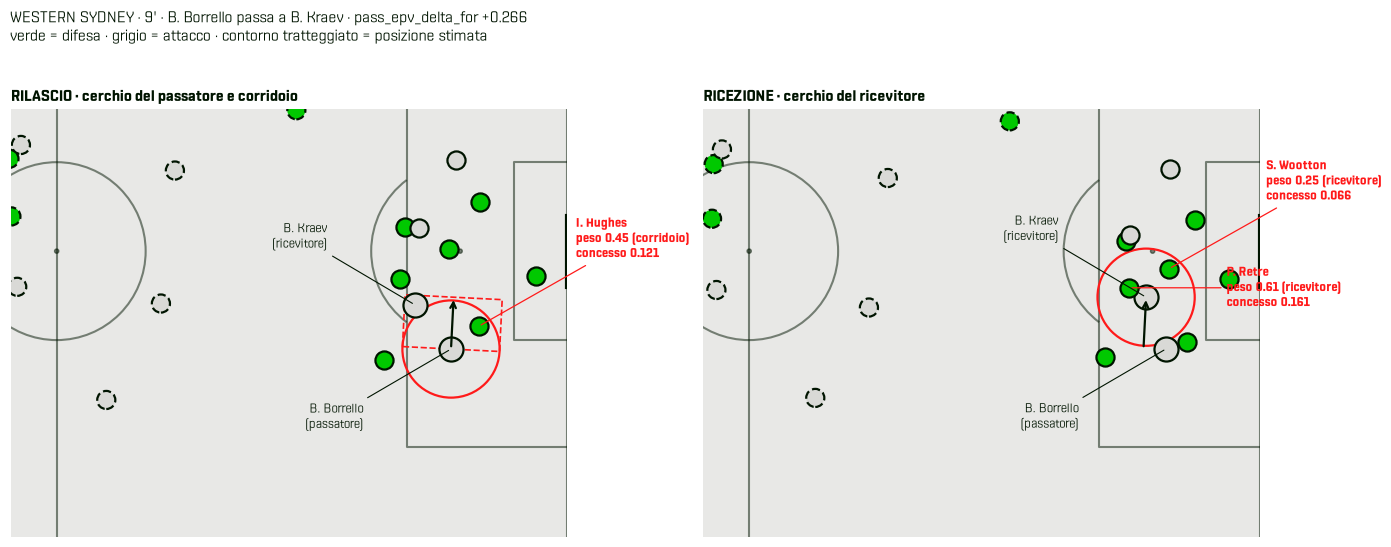

,area,peso,osservato,valore,concesso,nome
difensore,,,,,,
42510,ricevitore,0.248804,1.0,0.2663,0.066256,S. Wootton
51046,ricevitore,0.605067,1.0,0.2663,0.161129,P. Retre
698137,corridoio,0.454407,1.0,0.2663,0.121009,I. Hughes


In [5]:
def disegna_passaggio(match_id, event_id, raggio_vista=22):
    meta = data.load_match_meta(match_id)
    squadra = {p["id"]: p["team_id"] for p in meta["players"]}
    nome = {p["id"]: p.get("short_name") or p.get("last_name") for p in meta["players"]}
    de = data.load_dynamic_events(match_id)
    pp = de[de.event_type == "player_possession"].sort_values(["period", "frame_start"]).reset_index(drop=True)
    k = pp.index[pp.event_id == event_id][0]
    p, q = pp.iloc[k], pp.iloc[k + 1]
    f0, col, X, Y, D, _ = calcola_tau.carica_tracking(match_id)
    i_rel, i_ric = int(p.frame_end) - f0, int(q.frame_start) - f0
    a = X[i_rel, col[p.player_id]], Y[i_rel, col[p.player_id]]
    b = X[i_ric, col[q.player_id]], Y[i_ric, col[q.player_id]]
    coinv = COINV[(COINV.match_id == match_id) & (COINV.event_id == event_id)].set_index("difensore")

    with plt.rc_context({"font.family": "Shentox"}):
        pitch = Pitch(pitch_type="skillcorner", pitch_length=meta["pitch_length"], pitch_width=meta["pitch_width"],
                      pitch_color=CAMPO, line_color=TESTO, line_alpha=0.5, linewidth=1.5)
        fig, assi = pitch.draw(nrows=1, ncols=2, figsize=(14, 6))
        fig.set_facecolor("white")
        cx, cy = (a[0] + b[0]) / 2, (a[1] + b[1]) / 2
        for ax, i, titolo in ((assi[0], i_rel, "RILASCIO · cerchio del passatore e corridoio"),
                              (assi[1], i_ric, "RICEZIONE · cerchio del ricevitore")):
            if i == i_rel:
                ax.add_patch(Circle(a, R_AREA, fill=False, color=COLPA, lw=1.6))
                dx, dy = b[0] - a[0], b[1] - a[1]
                L = np.hypot(dx, dy); nx, ny = -dy / L * R_AREA, dx / L * R_AREA
                ax.add_patch(Polygon([(a[0] + nx, a[1] + ny), (b[0] + nx, b[1] + ny), (b[0] - nx, b[1] - ny),
                                      (a[0] - nx, a[1] - ny)], closed=True, fill=False, color=COLPA, lw=1.2, ls="--"))
            else:
                ax.add_patch(Circle(b, R_AREA, fill=False, color=COLPA, lw=1.6))
            ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->", color=TESTO, lw=1.6), zorder=5)
            for pid, j in col.items():
                if not np.isfinite(X[i, j]):
                    continue
                evid = pid in (p.player_id, q.player_id)
                ax.scatter(X[i, j], Y[i, j], s=300 if evid else 170,
                           color=ATTACCO if squadra[pid] == p.team_id else DIFESA,
                           edgecolors=TESTO, linewidths=1.6, linestyles="-" if D[i, j] else "--", zorder=4)
                if pid in coinv.index:
                    r = coinv.loc[pid]
                    if (i_ric if r.area == "ricevitore" else i_rel) == i:
                        n_et = sum("peso" in t.get_text() for t in ax.texts)
                        ax.annotate(f"{nome[pid]}\npeso {r.peso:.2f} ({r.area})\nconcesso {r.peso * r.valore:.3f}",
                                    (X[i, j], Y[i, j]), xytext=(X[i, j] + 10, Y[i, j] + 9 - 9 * n_et), color=COLPA,
                                    fontsize=9, va="center", fontweight="bold",
                                    arrowprops=dict(arrowstyle="-", color=COLPA, lw=0.9), zorder=6)
            for pid, etichetta, dy in ((p.player_id, "passatore", -7), (q.player_id, "ricevitore", 7)):
                j = col[pid]
                if np.isfinite(X[i, j]):
                    ax.annotate(f"{nome[pid]}\n({etichetta})", (X[i, j], Y[i, j]), xytext=(X[i, j] - 9, Y[i, j] + dy),
                                color=TESTO, fontsize=9, ha="right", va="center", zorder=6,
                                arrowprops=dict(arrowstyle="-", color=TESTO, lw=0.8))
            semi_l, semi_w = meta["pitch_length"] / 2, meta["pitch_width"] / 2
            vx = np.clip(cx, -semi_l + raggio_vista * 1.3, semi_l - raggio_vista * 1.3)
            vy = np.clip(cy, -semi_w + raggio_vista, semi_w - raggio_vista)
            ax.set_xlim(vx - raggio_vista * 1.3, vx + raggio_vista * 1.3)
            ax.set_ylim(vy - raggio_vista, vy + raggio_vista)
            ax.set_title(titolo, color=TESTO, fontsize=11, loc="left", fontweight="bold")
        fig.suptitle(f"{p.team_shortname.upper()} · {p.minute_start}' · {nome[p.player_id]} passa a {nome[q.player_id]} · "
                     f"pass_epv_delta_for {p.pass_epv_delta_for:+.3f}\n"
                     "verde = difesa · grigio = attacco · contorno tratteggiato = posizione stimata",
                     color=TESTO, x=0.01, ha="left", fontsize=11)
        plt.show()
    return coinv[["area", "peso", "osservato", "valore"]].assign(concesso=lambda t: t.peso * t.valore,
                                                                 nome=lambda t: t.index.map(nome))

disegna_passaggio(ESEMPIO.match_id, ESEMPIO.event_id)

**Cosa si vede.** Western Sydney, 9': Borrello serve Kraev a centro area con un
passaggio di 4–5 m, e l'EPV dell'attacco sale di 0,27 (da circa il 3% a circa il
30%). La regola fa quello che dice:

- **Retre**, il più vicino al ricevitore alla ricezione, prende il peso maggiore
  (0,61, concesso 0,161);
- **Hughes**, dentro il cerchio del passatore e il corridoio al rilascio, conta per
  il corridoio, dove il suo peso è più alto (0,45);
- **Wootton**, più lontano dal ricevitore, prende 0,25;
- il difensore poco sotto il cerchio della ricezione, a circa 6 m, resta fuori:
  il raggio di 5 m è un taglio netto.

**Un punto di metodo che la figura rende visibile.** I pesi non sono normalizzati:
qui sommano 1,31, quindi il valore concesso ripartito (0,348) supera il valore del
passaggio (0,266). È la definizione di *Blame* (p.9, formula 4): il peso misura
quanto ciascuno era coinvolto, non una quota. Se la pista va avanti, va deciso se
tenerla così o normalizzare, così che i valori dei difensori sommino al valore
concesso dalla squadra.

## 4. Stabilità: split-half fra partite

**Misure per difensore** (somme sulle sue partite, divise per l'esposizione):
- **colpa valutata** = Σ peso × valore sui passaggi riusciti con valore > 0 (*valued fault* del paper);
- **colpa grezza** = Σ peso sugli stessi passaggi (*raw fault*);
- **saldo** = merito valutato − colpa valutata, dove il merito è Σ peso × (−valore)
  sui passaggi che fanno scendere il valore, sugli intercetti e sui passaggi
  sbagliati con gioco interrotto (*valued involvement*).

Tutte per **100 passaggi avversari affrontati**, cioè i passaggi in gioco aperto
dell'avversario al cui rilascio il difensore era in campo.

**Il test.** Le partite di ogni difensore, in ordine di data, vanno alternate fra
la metà A e la metà B. Si calcola la correlazione fra le due metà sui difensori, e
la correzione di Spearman–Brown, $2r/(1+r)$, che stima l'affidabilità sull'insieme
delle partite. Poi lo stesso test dopo aver tolto a ogni difensore la media della
sua squadra, per separare il giocatore dalla squadra.

**Soglie fissate prima di vedere i risultati:** giocatori di movimento (portieri
esclusi), almeno 2 partite e almeno 100 passaggi avversari affrontati in ciascuna
metà.

In [6]:
from scipy.stats import pearsonr, spearmanr

DATA_PARTITA = {m["id"]: m["date_time"] for m in json.load(open(data.DATA / "matches.json"))}

# esposizione e ruoli, partita per partita
esp, ruolo, squadra_g, nome_g = [], {}, {}, {}
for mid in IDS:
    meta = data.load_match_meta(mid)
    sq = {p["id"]: p["team_id"] for p in meta["players"]}
    for pl in meta["players"]:
        ruolo[pl["id"]] = pl["player_role"]["acronym"]
        nome_g[pl["id"]] = pl.get("short_name") or pl.get("last_name")
        squadra_g[(mid, pl["id"])] = pl["team_id"]
    _, col, X, _, _, _ = calcola_tau.carica_tracking(mid)
    for r in PASS[(PASS.match_id == mid) & PASS.tracking_ok].itertuples():
        for pid, j in col.items():
            if sq.get(pid) not in (None, r.team_id) and 0 <= r.i_rel < len(X) and np.isfinite(X[r.i_rel, j]):
                esp.append((mid, pid))
ESP = pd.Series(esp).value_counts().rename("affrontati")
ESP.index = pd.MultiIndex.from_tuples(ESP.index, names=["match_id", "difensore"])

def partite(coinv):
    """Una riga per partita-difensore: colpa e merito, più esposizione, squadra, ruolo, metà."""
    c = coinv.copy()
    colpa = c.caso == "riuscito +"
    c["colpa_v"] = np.where(colpa, c.peso * c.valore, 0.0)
    c["colpa_r"] = np.where(colpa, c.peso, 0.0)
    c["merito_v"] = np.where(~colpa, c.peso * np.clip(-c.valore, 0, None), 0.0)
    PM = c.groupby(["match_id", "difensore"])[["colpa_v", "colpa_r", "merito_v"]].sum()
    PM = PM.reindex(ESP.index, fill_value=0.0).join(ESP).reset_index()
    PM["squadra"] = [squadra_g[(m, d)] for m, d in zip(PM.match_id, PM.difensore)]
    PM["ruolo"] = PM.difensore.map(ruolo)
    PM["data"] = PM.match_id.map(DATA_PARTITA)
    PM = PM[PM.ruolo != "GK"].copy()
    PM["metà"] = PM.sort_values("data").groupby("difensore").cumcount().mod(2).map({0: "A", 1: "B"})
    return PM, c, colpa

PM, c, colpa = partite(COINV)
print(f"{PM.difensore.nunique()} giocatori di movimento, {len(PM)} partite-giocatore")

256 giocatori di movimento, 586 partite-giocatore


In [7]:
MISURE = {"colpa valutata": "colpa_v", "colpa grezza": "colpa_r", "saldo": None}

def per_metà(pm):
    g = pm.groupby(["difensore", "metà"]).agg(colpa_v=("colpa_v", "sum"), colpa_r=("colpa_r", "sum"),
                                              merito_v=("merito_v", "sum"), affrontati=("affrontati", "sum"),
                                              partite=("match_id", "nunique"), squadra=("squadra", "first"))
    for k in ("colpa_v", "colpa_r", "merito_v"):
        g[k + "_100"] = 100 * g[k] / g.affrontati
    g["saldo_100"] = g.merito_v_100 - g.colpa_v_100
    return g.unstack("metà")

def sopra_soglia(H):
    return H[(H.partite.min(axis=1) >= 2) & (H.affrontati.min(axis=1) >= 100)]

H = sopra_soglia(per_metà(PM))
print(f"difensori sopra soglia: {len(H)} (partite per difensore: mediana {H.partite.sum(axis=1).median():.0f})")

def split_half(H, centra=False):
    righe = []
    for nome_m, k in (("colpa valutata", "colpa_v_100"), ("colpa grezza", "colpa_r_100"), ("saldo", "saldo_100")):
        a, b = H[(k, "A")].copy(), H[(k, "B")].copy()
        if centra:
            sq = H[("squadra", "A")]
            a, b = a - a.groupby(sq).transform("mean"), b - b.groupby(sq).transform("mean")
        r, p = pearsonr(a, b)
        rs, ps = spearmanr(a, b)
        righe.append({"misura": nome_m, "N": len(a), "r di Pearson": r, "p": p, "ρ di Spearman": rs,
                      "Spearman–Brown": 2 * r / (1 + r) if r > -1 else np.nan})
    return pd.DataFrame(righe).set_index("misura")

print("\nGrezza (giocatore + squadra):")
display(split_half(H).round(3))
print("Centrata sulla squadra (solo giocatore):")
display(split_half(H, centra=True).round(3))

difensori sopra soglia: 43 (partite per difensore: mediana 4)

Grezza (giocatore + squadra):


,N,r di Pearson,p,ρ di Spearman,Spearman–Brown
misura,,,,,
colpa valutata,43,0.028,0.857,0.110,0.055
colpa grezza,43,0.689,0.000,0.719,0.816
saldo,43,-0.099,0.527,-0.044,-0.220


Centrata sulla squadra (solo giocatore):


,N,r di Pearson,p,ρ di Spearman,Spearman–Brown
misura,,,,,
colpa valutata,43,0.030,0.849,0.183,0.058
colpa grezza,43,0.694,0.000,0.730,0.819
saldo,43,-0.084,0.592,0.033,-0.184


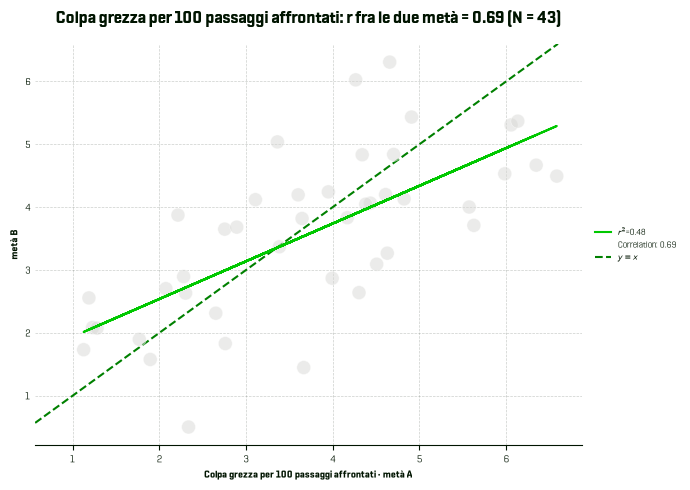

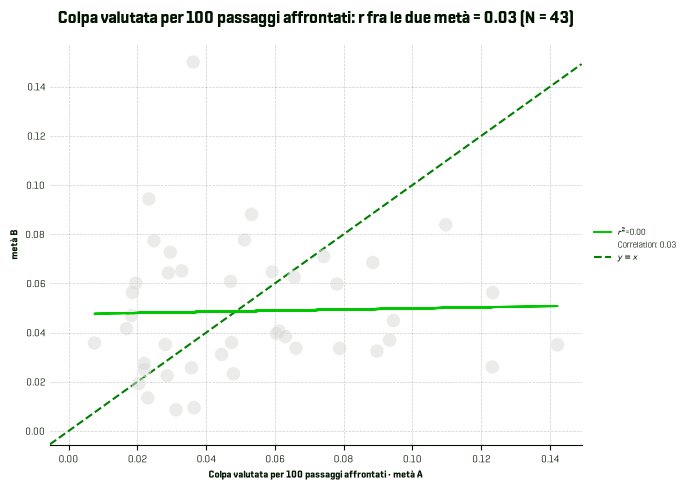

In [8]:
# Lo stesso test in figura, con lo scatter di skillcornerviz: un punto per difensore
from skillcornerviz.standard_plots import scatter_plot as scatter

for k, etichetta in (("colpa_r_100", "Colpa grezza per 100 passaggi affrontati"),
                     ("colpa_v_100", "Colpa valutata per 100 passaggi affrontati")):
    df_ab = pd.DataFrame({"player_id": H.index, "player_name": H.index.map(nome_g),
                          "metà A": H[(k, "A")].to_numpy(), "metà B": H[(k, "B")].to_numpy()})
    r = pearsonr(df_ab["metà A"], df_ab["metà B"])[0]
    scatter.plot_scatter(df_ab, x_metric="metà A", y_metric="metà B",
                         x_label=f"{etichetta} · metà A", y_label="metà B",
                         data_point_id="player_id", data_point_label="player_name",
                         avg_line=False, regression_line=True, y_equals_x_line=True,
                         plot_title=f"{etichetta}: r fra le due metà = {r:.2f} (N = {len(df_ab)})",
                         figsize=(7, 5))

In [9]:
# Controllo 1: la stabilità della colpa grezza viene dal ruolo?
print("ruoli dei 43 difensori:", H[("squadra", "A")].index.map(ruolo).value_counts().to_dict())
GRUPPO = {"CB": "centrale", "LCB": "centrale", "RCB": "centrale",
          "LB": "terzino", "RB": "terzino", "LWB": "terzino", "RWB": "terzino",
          "DM": "mediano", "LDM": "mediano", "RDM": "mediano", "CM": "mediano", "LCM": "mediano", "RCM": "mediano",
          "AM": "offensivo", "LM": "offensivo", "RM": "offensivo", "LW": "offensivo", "RW": "offensivo",
          "CF": "offensivo", "LCF": "offensivo", "RCF": "offensivo", "ST": "offensivo"}
gruppo = H.index.map(lambda d: GRUPPO.get(ruolo[d], "altro"))
print("gruppi:", pd.Series(gruppo).value_counts().to_dict())
for k, nome_m in (("colpa_r_100", "colpa grezza"), ("colpa_v_100", "colpa valutata")):
    a, b = H[(k, "A")], H[(k, "B")]
    print(f"\n{nome_m}: media per gruppo (A+B)/2 ->",
          ((a + b) / 2).groupby(gruppo).mean().round(3).to_dict())
    a_c, b_c = a - a.groupby(gruppo).transform("mean"), b - b.groupby(gruppo).transform("mean")
    r, pv = pearsonr(a_c, b_c)
    print(f"  centrata sul gruppo di ruolo: r = {r:.3f} (p = {pv:.3f}), Spearman–Brown = {2 * r / (1 + r):.3f}")

# Controllo 2: perché la colpa valutata non regge? Peso delle code
v = c.loc[colpa, "colpa_v"].sort_values(ascending=False)
print(f"\ncolpa valutata: l'1% delle righe difensore×passaggio porta il {v.head(int(len(v) * 0.01)).sum() / v.sum():.1%} "
      f"del totale; il 10% porta il {v.head(int(len(v) * 0.1)).sum() / v.sum():.1%}")

ruoli dei 43 difensori: {'CF': 7, 'LW': 7, 'RW': 5, 'RCB': 4, 'LB': 3, 'CB': 3, 'LCB': 3, 'LM': 3, 'RB': 2, 'RM': 2, 'DM': 1, 'AM': 1, 'RWB': 1, 'SUB': 1}
gruppi: {'offensivo': 25, 'centrale': 10, 'terzino': 6, 'mediano': 1, 'altro': 1}

colpa grezza: media per gruppo (A+B)/2 -> {'altro': 5.257, 'centrale': 2.027, 'mediano': 5.482, 'offensivo': 4.291, 'terzino': 3.149}
  centrata sul gruppo di ruolo: r = 0.409 (p = 0.006), Spearman–Brown = 0.581

colpa valutata: media per gruppo (A+B)/2 -> {'altro': 0.089, 'centrale': 0.062, 'mediano': 0.071, 'offensivo': 0.044, 'terzino': 0.051}
  centrata sul gruppo di ruolo: r = -0.007 (p = 0.966), Spearman–Brown = -0.014



colpa valutata: l'1% delle righe difensore×passaggio porta il 18.7% del totale; il 10% porta il 63.1%


**Cosa si vede.**

- **La colpa valutata non è stabile.** Fra le due metà delle partite r = 0,03
  (Spearman–Brown 0,06), e non cambia togliendo la media di squadra. Lo stesso
  vale per il saldo merito − colpa. **Su questi dati, il valore concesso per
  difensore come classifica di giocatori è rumore.**
- **Il motivo più probabile sono le code.** L'1% delle righe difensore × passaggio
  porta il 18,7% della colpa valutata, il 10% ne porta il 63%. Con 4 partite a
  testa (mediana) pochi passaggi molto pericolosi decidono tutto, e cadono a
  caso fra le due metà.
- **La colpa grezza è stabile** (r = 0,69, Spearman–Brown 0,82), anche togliendo
  la media di squadra (0,69). Però misura **quanto spesso un giocatore è vicino**
  ai passaggi che fanno salire il valore, e dipende molto da dove gioca. Togliendo
  la media del gruppo di ruolo resta r = 0,41: una parte individuale c'è, ma
  questo controllo non è affidabile (punto sotto).
- **Le etichette di ruolo di SkillCorner qui non reggono un controllo per ruolo.**
  "CF" compare 104 volte su 40 squadre-partita (2,6 centravanti per squadra),
  "CM" mai, e 119 giocatori su 307 cambiano ruolo fra partite. Il raggruppamento
  sopra è quindi grossolano.
- **Un artefatto della regola presa così com'è.** "Riuscito con valore > 0"
  include passaggi che spostano l'EPV di centesimi di punto, per esempio i
  passaggi in avanti dei centrali in costruzione. Così chi pressa la prima
  costruzione accumula colpa grezza su passaggi innocui: è uno dei motivi per cui
  gli attaccanti risultano molto "coinvolti".

**Cosa implica per la pista, da discutere:** come classifica individuale su 20
partite la versione valutata non regge. Restano tre strade:
1. alzare la soglia di valore e lavorare solo sui passaggi davvero pericolosi;
2. spostare l'unità dal giocatore all'azione o alla zona: dove e come si concede,
   non chi;
3. tenere la colpa grezza, che è stabile, con il problema di separarla dal
   ruolo.

## 5. EPV di SkillCorner contro due valori aperti

Il passo 4 ha detto che la colpa valutata non è stabile. La domanda ora è **da dove
viene l'instabilità**: dall'EPV, che è chiuso, o da qualunque misura di valore?
Stessa geometria, stesse soglie, tre misure del valore di un passaggio riuscito:

| Valore | Cosa misura | Code |
|---|---|---|
| `pass_epv_delta_for` | EPV di SkillCorner, rilascio → ricezione (chiuso) | pesanti |
| **Δ distanza** | metri guadagnati verso la porta avversaria, dal passatore al rilascio al ricevitore alla ricezione (aperto) | leggere |
| **Δ angolo di porta** | variazione dell'angolo sotto cui si vede la porta, in gradi (aperto); è la feature geometrica classica degli xG | pesanti vicino alla porta |

Il segno decide il caso, come prima: valore > 0 → colpa a passatore, corridoio e
ricevitore; ≤ 0 → merito al passatore. Il confronto riguarda solo la colpa,
perché merito e intercetti non hanno un valore aperto equivalente.

In [10]:
def angolo_porta(x, y, gx, semi_porta=7.32 / 2):
    v1x, v1y, v2x, v2y = gx - x, semi_porta - y, gx - x, -semi_porta - y
    coseno = (v1x * v2x + v1y * v2y) / (np.hypot(v1x, v1y) * np.hypot(v2x, v2y))
    return np.degrees(np.arccos(np.clip(coseno, -1, 1)))

gx = np.where(PASS.lato == "left_to_right", PASS.L / 2, -PASS.L / 2)
PASS["v_dist"] = np.hypot(PASS.ax - gx, PASS.ay) - np.hypot(PASS.bx - gx, PASS.by)
PASS["v_ang"] = angolo_porta(PASS.bx, PASS.by, gx) - angolo_porta(PASS.ax, PASS.ay, gx)

riu = PASS[(PASS.esito == "riuscito") & PASS.tracking_ok]
print(f"passaggi riusciti: {len(riu)}; quota con valore > 0 — EPV {(riu.valore > 0).mean():.1%}, "
      f"Δ distanza {(riu.v_dist > 0).mean():.1%}, Δ angolo {(riu.v_ang > 0).mean():.1%}")
print("Spearman fra le misure sui passaggi riusciti:")
display(riu[["valore", "v_dist", "v_ang"]].corr(method="spearman").round(3))

DEFINIZIONI = {"EPV (SkillCorner)": "valore", "Δ distanza (aperto)": "v_dist", "Δ angolo di porta (aperto)": "v_ang"}
righe = []
for nome_v, col_v in DEFINIZIONI.items():
    pm_v, c_v, colpa_v = partite(assegna(PASS, AREE, col_v))
    tab = split_half(sopra_soglia(per_metà(pm_v))).loc[["colpa valutata", "colpa grezza"]]
    code_ = c_v.loc[colpa_v, "colpa_v"].sort_values(ascending=False)
    for misura, rr in tab.iterrows():
        righe.append({"valore": nome_v, "misura": misura, "N": int(rr.N), "r": rr["r di Pearson"],
                      "p": rr.p, "Spearman–Brown": rr["Spearman–Brown"],
                      "quota del 10% più alto": code_.head(int(len(code_) * 0.1)).sum() / code_.sum()
                      if misura == "colpa valutata" else np.nan})
CONFRONTO = pd.DataFrame(righe)
display(CONFRONTO.round(3))

passaggi riusciti: 11899; quota con valore > 0 — EPV 58.2%, Δ distanza 55.4%, Δ angolo 50.8%
Spearman fra le misure sui passaggi riusciti:


,valore,v_dist,v_ang
valore,1.000,0.612,0.441
v_dist,0.612,1.000,0.692
v_ang,0.441,0.692,1.000


,valore,misura,N,r,p,Spearman–Brown,quota del 10% più alto
0,EPV (SkillCorner),colpa valutata,43,0.028,0.857,0.055,0.631
1,EPV (SkillCorner),colpa grezza,43,0.689,0.000,0.816,NaN
2,Δ distanza (aperto),colpa valutata,43,0.355,0.019,0.524,0.368
3,Δ distanza (aperto),colpa grezza,43,0.630,0.000,0.773,NaN
4,Δ angolo di porta (aperto),colpa valutata,43,0.018,0.911,0.034,0.650
5,Δ angolo di porta (aperto),colpa grezza,43,0.609,0.000,0.757,NaN


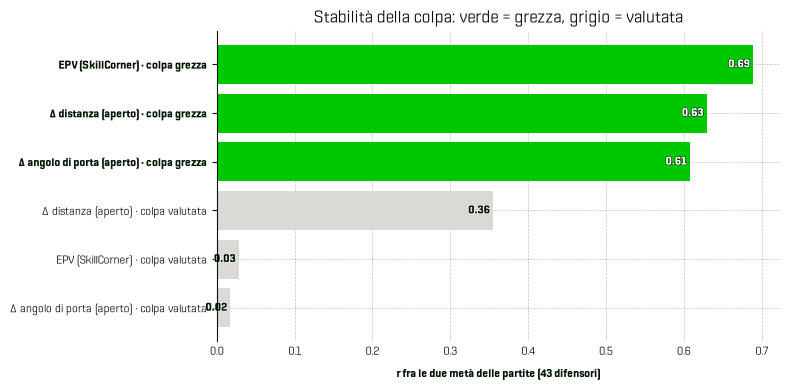

(<Figure size 800x400 with 1 Axes>,
 <Axes: title={'center': 'Stabilità della colpa: verde = grezza, grigio = valutata'}, xlabel='r fra le due metà delle partite (43 difensori)'>)

In [11]:
# In figura, con il grafico a barre di skillcornerviz: r fra le due metà per ogni combinazione
from skillcornerviz.standard_plots import bar_plot as bar

df_bar = CONFRONTO.assign(player_name=CONFRONTO.valore + " · " + CONFRONTO.misura)
bar.plot_bar_chart(df_bar, metric="r", label="r fra le due metà delle partite (43 difensori)",
                   data_point_id="player_name", data_point_label="player_name",
                   primary_highlight_group=df_bar.loc[df_bar.misura == "colpa grezza", "player_name"].tolist(),
                   add_bar_values=True, figsize=(8, 4), fontsize=8,
                   plot_title="Stabilità della colpa: verde = grezza, grigio = valutata")

**Cosa si vede.**

- **L'instabilità non dipende dall'EPV chiuso, ma dalle code.** Con il Δ angolo di
  porta, misura aperta e con code pesanti quanto l'EPV (il 10% delle righe porta il
  65% del totale), la colpa valutata è instabile allo stesso modo (r = 0,02). Con
  il Δ distanza, misura aperta e con code leggere (37%), diventa moderatamente
  stabile (r = 0,36, p = 0,02; Spearman–Brown 0,52).
- **La colpa grezza è stabile con tutte e tre** (0,61–0,69): la geometria regge,
  qualunque sia il valore che decide il segno.
- **Le tre misure di valore sono parenti, non gemelle.** Spearman EPV–Δ distanza
  0,61, EPV–Δ angolo 0,44. L'EPV vede più della semplice avanzata, ed è proprio il
  pezzo in più che ha code pesanti.

**In sintesi, per la verifica:** su 20 partite e con 4 partite a difensore, una
classifica di giocatori per valore concesso regge solo con una misura di valore
dalle code leggere, e anche così solo in parte. Il limite è il campione rispetto
alle code, non la scatola chiusa di SkillCorner. Le strade aperte sono quelle già
annotate nel passo 4: cambiare unità (zona, tipo di azione, squadra invece del
giocatore), usare la colpa grezza separandola dal ruolo, o un valore dalle code
leggere.